In [1]:
%pip install tensorflow matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import imdb
from tensorflow.keras.utils import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:

keras.utils.set_random_seed(42)

VOCAB_SIZE = 10_000
MAX_LENGTH = 200
EMBEDDING_DIM = 64
RNN_UNITS = 32

BATCH_SIZE = 128
EPOCHS = 8

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.19.0
Available GPUs: []


In [3]:
(x_train_full, y_train_full), (x_test_raw, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Original training reviews:", len(x_train_full))
print("Test reviews:", len(x_test_raw))

print("\nFirst review: first 20 token IDs")
print(x_train_full[0][:20])

print("\nFirst review label:", y_train_full[0])
print("Label meaning: 0 = Negative, 1 = Positive")

Original training reviews: 25000
Test reviews: 25000

First review: first 20 token IDs
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]

First review label: 1
Label meaning: 0 = Negative, 1 = Positive


In [4]:
x_train_raw, x_val_raw, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training reviews:", len(x_train_raw))
print("Validation reviews:", len(x_val_raw))
print("Test reviews:", len(x_test_raw))

Training reviews: 20000
Validation reviews: 5000
Test reviews: 25000


In [5]:
def prepare_sequences(sequences):
    return pad_sequences(
        sequences,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post",
        value=0
    )

x_train = prepare_sequences(x_train_raw)
x_val = prepare_sequences(x_val_raw)
x_test = prepare_sequences(x_test_raw)

print("Training input shape:", x_train.shape)
print("Validation input shape:", x_val.shape)
print("Test input shape:", x_test.shape)

Training input shape: (20000, 200)
Validation input shape: (5000, 200)
Test input shape: (25000, 200)


In [6]:
model = keras.Sequential([
    keras.Input(
        shape=(MAX_LENGTH,),
        dtype="int32",
        name="review_tokens"
    ),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="word_embedding"
    ),

    layers.Bidirectional(
        layers.SimpleRNN(RNN_UNITS),
        merge_mode="concat",
        name="bidirectional_rnn"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        32,
        activation="relu",
        name="dense_features"
    ),

    layers.Dense(
        1,
        activation="sigmoid",
        name="sentiment_probability"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)           │ (None, 200, 64)             │         640,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_rnn (Bidirectional)    │ (None, 64)                  │           6,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_features (Dense)               │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sentiment_probability (Dense)        │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 648,321 (2.47 MB)

 Trainable params: 648,321 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001,
        global_clipnorm=1.0
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

In [8]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 14s 65ms/step - accuracy: 0.6160 - auc: 0.6730 - loss: 0.6434 - val_accuracy: 0.7126 - val_auc: 0.8420 - val_loss: 0.5783
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 60ms/step - accuracy: 0.8275 - auc: 0.8912 - loss: 0.4143 - val_accuracy: 0.8278 - val_auc: 0.9002 - val_loss: 0.4325
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.8788 - auc: 0.9358 - loss: 0.3168 - val_accuracy: 0.8170 - val_auc: 0.9020 - val_loss: 0.3995
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 60ms/step - accuracy: 0.9127 - auc: 0.9624 - loss: 0.2399 - val_accuracy: 0.8362 - val_auc: 0.9103 - val_loss: 0.4000
Epoch 5/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.9262 - auc: 0.9711 - loss: 0.2093 - val_accuracy: 0.8312 - val_auc: 0.8976 - val_loss: 0.5015


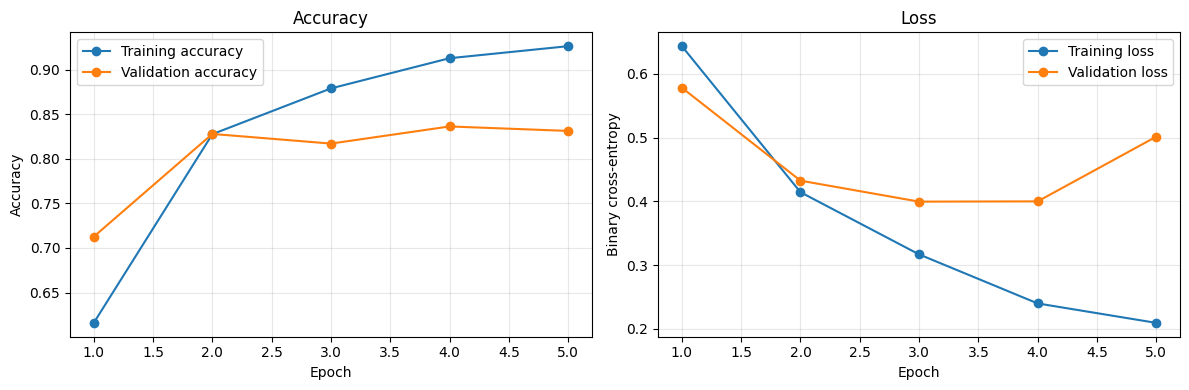

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs_run = range(1, len(history.history["loss"]) + 1)

axes[0].plot(
    epochs_run,
    history.history["accuracy"],
    marker="o",
    label="Training accuracy"
)
axes[0].plot(
    epochs_run,
    history.history["val_accuracy"],
    marker="o",
    label="Validation accuracy"
)
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs_run,
    history.history["loss"],
    marker="o",
    label="Training loss"
)
axes[1].plot(
    epochs_run,
    history.history["val_loss"],
    marker="o",
    label="Validation loss"
)
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary cross-entropy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
test_results = model.evaluate(
    x_test,
    y_test,
    batch_size=BATCH_SIZE,
    return_dict=True,
    verbose=1
)

for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")

196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8076 - auc: 0.8893 - loss: 0.4213
accuracy: 0.8076
auc: 0.8893
loss: 0.4213


196/196 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step
              precision    recall  f1-score   support

    Negative     0.8090    0.8053    0.8072     12500
    Positive     0.8062    0.8099    0.8080     12500

    accuracy                         0.8076     25000
   macro avg     0.8076    0.8076    0.8076     25000
weighted avg     0.8076    0.8076    0.8076     25000



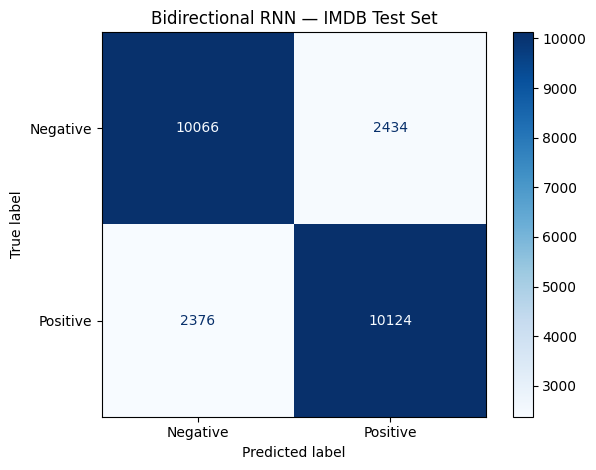

In [11]:
test_probabilities = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=1
).ravel()

test_predictions = (test_probabilities >= 0.5).astype("int32")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        digits=4,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Bidirectional RNN — IMDB Test Set")
plt.tight_layout()
plt.show()

In [12]:
word_index = imdb.get_word_index()

index_to_word = {
    index + 3: word
    for word, index in word_index.items()
}

index_to_word.update({
    0: "[PAD]",
    1: "[START]",
    2: "[OOV]",
    3: "[UNUSED]"
})

def decode_review(sequence):
    return " ".join(
        index_to_word.get(int(token), "[OOV]")
        for token in sequence
        if token != 0
    )

for i in range(3):
    probability = float(test_probabilities[i])

    predicted_label = "Positive" if probability >= 0.5 else "Negative"
    actual_label = "Positive" if y_test[i] == 1 else "Negative"

    print(f"\nReview {i + 1}")
    print("-" * 70)
    print(decode_review(x_test[i]))
    print("\nActual sentiment:", actual_label)
    print("Predicted sentiment:", predicted_label)
    print(f"Positive probability: {probability:.4f}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 2s 1us/step

Review 1
----------------------------------------------------------------------
[START] please give this one a miss br br [OOV] [OOV] and the rest of the cast rendered terrible performances the show is flat flat flat br br i don't know how michael madison could have allowed this one on his plate he almost seemed to know this wasn't going to work out and his performance was quite [OOV] so all you madison fans give this a miss

Actual sentiment: Negative
Predicted sentiment: Negative
Positive probability: 0.0988

Review 2
----------------------------------------------------------------------
[START] this film requires a lot of patience because it focuses on mood and character development the plot is very simple and many of the scenes take place on the same set in frances [OOV] the sandy dennis character apartment but the film builds to a disturbing climax br br the characters create an atmosphere [OOV] with sexual tension and psychologica